# 02 · Spectral structure, PSD, and scalp maps

## Goal
Estimate spectra correctly, integrate power in a frequency band, and distinguish channel-level descriptions from population evidence.

**Scope:** a reproducible teaching analysis of public recordings, not clinical validation. Downloaded data are cached locally; no synthetic fallback is used. Each notebook runs independently.

## Setup
Use the environment in `README.md`. The default sample is deliberately small; results are descriptive unless explicitly stated otherwise.

In [2]:
from pathlib import Path
import sys
course_dir = Path.cwd() if (Path.cwd() / 'course_utils.py').exists() else Path.cwd() / 'EEG_from_ground_up'
assert (course_dir / 'course_utils.py').exists(), 'Open this notebook from the course folder or project root.'
sys.path.insert(0, str(course_dir.resolve()))
from course_utils import ROOT, DATA, OUTPUT, SEED, load_run, versions, style, save_table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from IPython.display import display
%matplotlib inline
style()
rng = np.random.default_rng(SEED)
display(versions().to_frame())

,version
numpy,2.5.4
scipy,1.18.1
pandas,3.0.6
matplotlib,3.11.2
mne,1.13.2
moabb,1.7.2
pyriemann,0.12
braindecode,1.8.1
torch,2.14.1
scikit-learn,1.9.1


## Steps

### 1. Load paired baseline recordings
Use one participant, runs 1 and 2. This is a within-person, two-recording comparison, not a randomized group experiment. We remove each channel’s temporal mean through Welch’s detrending; no narrow bandpass is applied before inspecting the spectrum.

In [4]:
from scipy.signal import welch
from scipy.integrate import trapezoid
SUBJECT=1
recordings={'Eyes open':load_run(SUBJECT,1),'Eyes closed':load_run(SUBJECT,2)}
recordings={name:r.copy().set_eeg_reference('average',projection=False,verbose=False) for name,r in recordings.items()}
fs=recordings['Eyes open'].info['sfreq']

/Users/trush/Documents/Research/Synaptrix/synaptrixmotorimagerydata/EEG_from_ground_up/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2. Welch spectra and spectral resolution
Welch averages modified periodograms. PSD units are V²/Hz; µV²/Hz requires multiplication by 10¹². A 4 s segment has Fourier-bin spacing 0.25 Hz. Zero padding makes a denser frequency grid but does not add independent spectral information. Adjacent overlapping segments are not independent replicates.
For a tapered segment of $N$ samples, a two-sided periodogram uses $|\mathrm{FFT}(wx)|^2/(f_s\sum_n w_n^2)$. A one-sided estimate doubles interior positive-frequency bins, while preserving DC and Nyquist conventions. Welch then averages across segments. `scipy.signal.welch` handles this normalization.

**Power versus amplitude:** multiplying voltage by 10 multiplies power by 100. Therefore voltage uses $20\log_{10}$ for amplitude ratios, while power uses $10\log_{10}$. Absolute band power integrates the PSD; relative band power divides by power in a declared reference band. Peaks sit on an aperiodic background, so a band-power change does not necessarily mean a stronger narrowband oscillator.

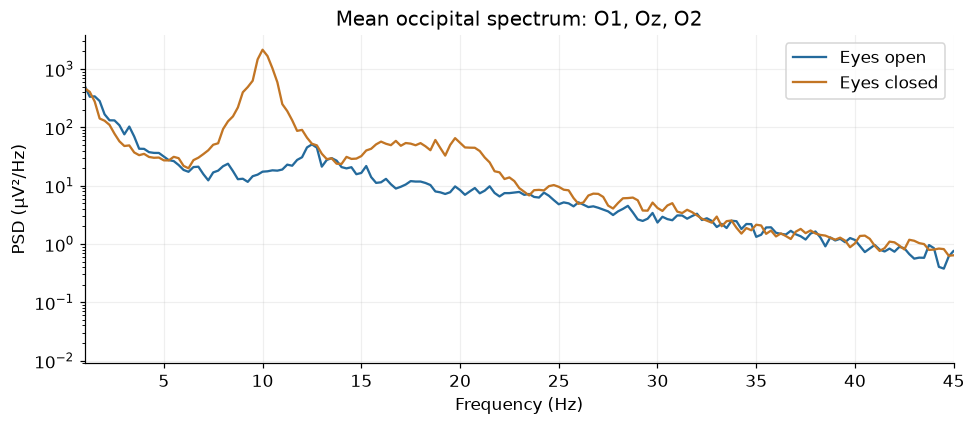

In [6]:
spectra={}
fig,ax=plt.subplots()
for label,r in recordings.items():
    f,p=welch(r.get_data(),fs=fs,nperseg=int(4*fs),noverlap=int(2*fs),detrend='constant',axis=-1)
    spectra[label]=(f,p)
    occ=[r.ch_names.index(ch) for ch in ['O1','Oz','O2']]
    ax.semilogy(f,p[occ].mean(axis=0)*1e12,label=label)
ax.set(xlim=(1,45),xlabel='Frequency (Hz)',ylabel='PSD (µV²/Hz)',title='Mean occipital spectrum: O1, Oz, O2')
ax.legend(); plt.tight_layout(); plt.show()

### 3. Integrate band power and map its spatial distribution
P[a,b] = ∫ₐᵇ S(f)df. Here alpha is operationally defined as 8–13 Hz, rather than assuming every person has identical boundaries. A topomap interpolates scalp values; it does not locate cortical generators.

,condition,channel,alpha_power_uV2
60,Eyes open,O1,116.352975
61,Eyes open,Oz,104.900302
62,Eyes open,O2,127.105053
124,Eyes closed,O1,2688.686261
125,Eyes closed,Oz,2063.471274
126,Eyes closed,O2,2656.315526


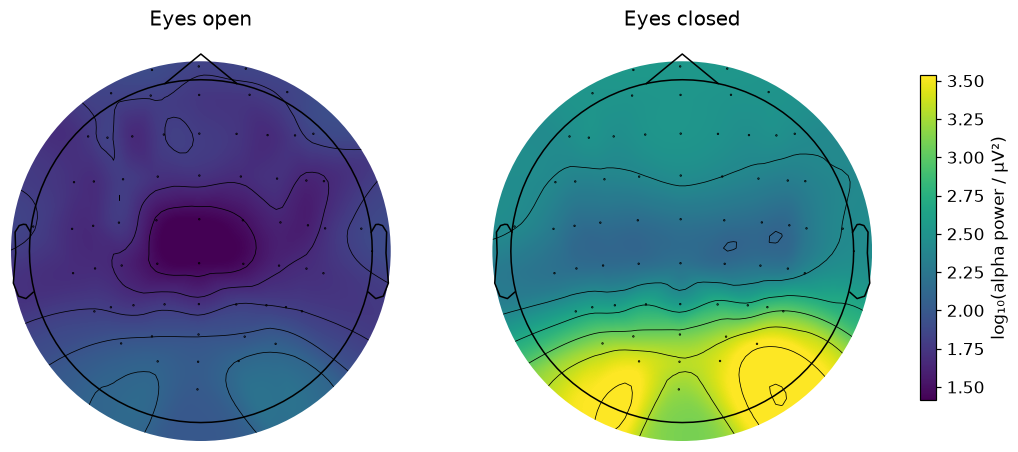

Mean occipital channel-wise closed/open alpha ratio: 21.226


In [8]:
rows=[]; alpha={}
for label,(f,p) in spectra.items():
    mask=(f>=8)&(f<=13)
    alpha[label]=trapezoid(p[:,mask],f[mask],axis=-1)*1e12
    for ch,power in zip(recordings[label].ch_names,alpha[label]):
        rows.append({'condition':label,'channel':ch,'alpha_power_uV2':power})
table=pd.DataFrame(rows)
display(save_table(table,'02_alpha_power.csv').query("channel in ['O1','Oz','O2']"))
fig,axes=plt.subplots(1,2,figsize=(10,4),layout='constrained')
values=[np.log10(alpha[name]) for name in recordings]
vmin,vmax=min(v.min() for v in values),max(v.max() for v in values)
for ax,(name,r),v in zip(axes,recordings.items(),values):
    im,_=mne.viz.plot_topomap(v,r.info,axes=ax,show=False,vlim=(vmin,vmax),cmap='viridis')
    ax.set_title(name)
fig.colorbar(im,ax=axes,label='log₁₀(alpha power / µV²)',shrink=.8); plt.show()
ratio=alpha['Eyes closed']/alpha['Eyes open']
occ=[recordings['Eyes open'].ch_names.index(c) for c in ['O1','Oz','O2']]
print(f'Mean occipital channel-wise closed/open alpha ratio: {ratio[occ].mean():.3f}')

### 4. Compare Welch and multitaper estimates
Multitaper averages across orthogonal tapers and trades spectral resolution for reduced variance. The methods need not produce identical curves. Use the same signal, units, and frequency range for comparison.

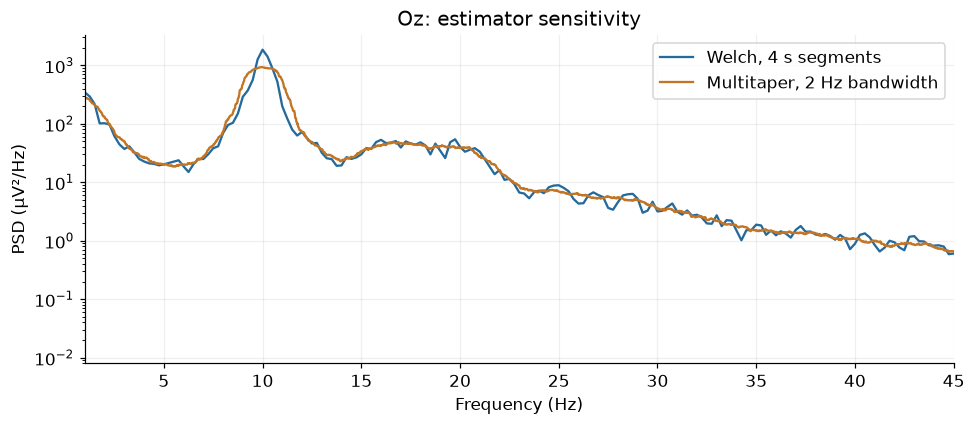

In [10]:
r=recordings['Eyes closed']
p_mt,f_mt=mne.time_frequency.psd_array_multitaper(r.get_data(picks=['Oz'])[0],sfreq=fs,
    fmin=1,fmax=45,bandwidth=2,normalization='full',verbose=False)
f,p=spectra['Eyes closed']; idx=r.ch_names.index('Oz')
fig,ax=plt.subplots(); ax.semilogy(f,p[idx]*1e12,label='Welch, 4 s segments')
ax.semilogy(f_mt,p_mt*1e12,label='Multitaper, 2 Hz bandwidth')
ax.set(xlim=(1,45),xlabel='Frequency (Hz)',ylabel='PSD (µV²/Hz)',title='Oz: estimator sensitivity')
ax.legend(); plt.tight_layout(); plt.show()

## Checks
Integrated PSD should approximately agree with signal variance. Small deviations arise from segment averaging, detrending, and tapering; exact equality is not expected for this Welch estimate.

In [12]:
f,p=spectra['Eyes closed']; r=recordings['Eyes closed']
variance=r.get_data().var(axis=1)
ratio_psd=trapezoid(p,f,axis=-1)/variance
assert np.isfinite(p).all() and (p>=0).all()
print('Median integrated-PSD / full-recording variance:',np.median(ratio_psd))

Median integrated-PSD / full-recording variance: 0.957145483580073


## Next Steps
Notebook 03 inspects how cleaning changes spectra and waveforms.

**Exercises:** repeat with 2 s and 8 s Welch segments. Compare alpha-power sensitivity, not just appearance. Add another participant and keep each participant’s result separate before computing a group summary. An alpha increase is a common expectation, not a result to force through preprocessing.

## Sources and further reading
Original teaching code; the resources below provide APIs, methodological guidance, and dataset provenance. No tutorial text or full external notebook is reproduced.

- [PhysioNet dataset and protocol](https://physionet.org/content/eegmmidb/1.0.0/)
- [MNE spectral analysis](https://mne.tools/stable/auto_tutorials/time-freq/20_sensors_time_frequency.html)